# DSCI 552 - Homework 4
- **Name:** Vaidik Danda
- **GitHub Username:** vaidikdanda-png

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 code, needed by Part 2)

In [1]:
import glob
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy.stats import bootstrap
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

### 1(a) Loading the AReM data

In [2]:
DATA_DIR = '../data/AReM'   # relative to the notebook/ folder
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
ACTIVITIES = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

def load_file(path):
    # Minor cleaning: a few files use spaces instead of commas or have a trailing separator.
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            values = [v for v in line.replace(',', ' ').split() if v]
            rows.append([float(v) for v in values[:7]])
    return pd.DataFrame(rows, columns=['time'] + SERIES)[SERIES]

records = []
for activity in ACTIVITIES:
    for path in sorted(glob.glob(os.path.join(DATA_DIR, activity, 'dataset*.csv'))):
        num = int(os.path.basename(path)[len('dataset'):-len('.csv')])
        records.append({'activity': activity, 'dataset': num, 'data': load_file(path)})

print('Instances loaded:', len(records))
print('Rows per instance:', sorted({len(r['data']) for r in records}))

Instances loaded: 88
Rows per instance: [479, 480]


### 1(b) Train/test split
Test data: datasets 1-2 of `bending1` and `bending2`, and datasets 1-3 of every other activity. Everything else is training data.

In [3]:
def is_test(activity, num):
    return num <= (2 if activity.startswith('bending') else 3)

for r in records:
    r['split'] = 'test' if is_test(r['activity'], r['dataset']) else 'train'

counts = pd.DataFrame([(r['activity'], r['split']) for r in records], columns=['activity', 'split'])
display(pd.crosstab(counts['activity'], counts['split'], margins=True))

split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


### 1(c) Feature extraction

#### i. Common time-domain features
Typical time-domain features for time series classification:
- **Location:** mean, median, minimum, maximum, first and third quartiles (and other percentiles).
- **Spread:** standard deviation, variance, range, interquartile range, mean absolute deviation.
- **Shape:** skewness, kurtosis.
- **Energy / magnitude:** root mean square, energy (sum of squares), absolute sum.
- **Change over time:** number of zero / mean crossings, number of peaks, slope of a fitted line, mean absolute first difference, autocorrelation at a given lag.

#### ii. Extracting min, max, mean, median, std, Q1 and Q3 for all 6 series

In [4]:
FEATURE_FUNCS = {
    'min': np.min,
    'max': np.max,
    'mean': np.mean,
    'median': np.median,
    'std': lambda x: np.std(x, ddof=1),
    '1st_quart': lambda x: np.percentile(x, 25),
    '3rd_quart': lambda x: np.percentile(x, 75),
}

def features_of(frame, funcs, suffix=''):
    out = {}
    for k, col in enumerate(SERIES, start=1):
        x = frame[col].to_numpy()
        for name, f in funcs.items():
            out[f'{name}{k}{suffix}'] = f(x)
    return out

feat = pd.DataFrame([features_of(r['data'], FEATURE_FUNCS) for r in records])
feat.insert(0, 'activity', [r['activity'] for r in records])
feat.insert(1, 'split', [r['split'] for r in records])
feat.index = pd.RangeIndex(1, len(feat) + 1, name='Instance')
FEATURE_COLS = [c for c in feat.columns if c not in ('activity', 'split')]
print(feat.shape)
display(feat.head())

(88, 44)


,activity,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,...,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,0.43,0.322605,0.00,...,1.120,27.25,38.25,34.311292,35.0,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
2,bending1,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,0.47,0.289158,0.00,...,1.145,27.67,38.50,33.024583,33.0,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
3,bending1,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,0.47,0.338690,0.00,...,0.830,29.00,38.50,35.588458,36.0,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
4,bending1,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,0.50,0.630860,0.00,...,1.300,20.00,38.67,33.493917,35.0,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
5,bending1,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,0.50,0.405469,0.43,...,1.120,23.67,37.50,29.857083,30.0,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


#### iii. Standard deviation of each feature with a 90% bootstrap confidence interval

In [5]:
rows = []
for col in FEATURE_COLS:
    x = feat[col].to_numpy()
    ci = bootstrap((x,), lambda s, axis: np.std(s, ddof=1, axis=axis), n_resamples=5000,
                   confidence_level=0.90, method='percentile', random_state=552).confidence_interval
    rows.append({'feature': col, 'std': np.std(x, ddof=1), '90% CI low': ci.low, '90% CI high': ci.high})

std_ci = pd.DataFrame(rows).set_index('feature').round(3)
display(std_ci)

,std,90% CI low,90% CI high
feature,,,
min1,9.570,8.287,10.801
max1,4.394,3.337,5.295
mean1,5.336,4.694,5.888
median1,5.440,4.787,5.990
std1,1.772,1.573,1.950
1st_quart1,6.154,5.568,6.622
3rd_quart1,5.139,4.318,5.853
min2,0.000,0.000,0.000
max2,5.063,4.632,5.404


#### iv. Choosing three features
I use **minimum, mean and maximum**. Together they describe the level of a series (mean) and the range it moves in (min and max). Mean, median and the quartiles are almost redundant with each other, and min/max add the extremes, which separate quiet activities (lying, sitting, bending) from active ones (walking, cycling).

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

In [6]:
CHOSEN = {'min': np.min, 'mean': np.mean, 'max': np.max}
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
LS = range(1, 21)

def split_features(l):
    # Break every series into l (approximately) equal parts and extract the chosen features of each part.
    rows = []
    for r in records:
        row = {}
        for part, idx in enumerate(np.array_split(np.arange(len(r['data'])), l), start=1):
            row.update(features_of(r['data'].iloc[idx], CHOSEN, '' if l == 1 else f'_p{part}'))
        rows.append(row)
    df = pd.DataFrame(rows)
    df['activity'] = [r['activity'] for r in records]
    df['bending'] = df['activity'].str.startswith('bending').astype(int)
    df['split'] = [r['split'] for r in records]
    return df

DATA = {l: split_features(l) for l in LS}

def get_xy(l, split, target='bending'):
    df = DATA[l][DATA[l]['split'] == split]
    X = df.drop(columns=['activity', 'bending', 'split'])
    return X, df[target]

def logreg(**kw):
    # C = inf removes the L2 penalty; a small max_iter keeps separable problems from diverging.
    return LogisticRegression(C=np.inf, max_iter=200, **kw)

In [7]:
def report(model, X, y, title):
    # Confusion matrix and ROC curve(s) for a fitted model; returns (accuracy, AUC).
    prob = model.predict_proba(X)
    pred = model.classes_[prob.argmax(axis=1)]
    classes = model.classes_
    acc = accuracy_score(y, pred)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    names = ['other', 'bending'] if list(classes) == [0, 1] else classes
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=classes), display_labels=names).plot(
        ax=ax[0], colorbar=False, xticks_rotation=45)
    ax[0].set_title(f'{title}\naccuracy = {acc:.4f}')
    if len(classes) == 2:
        fpr, tpr, _ = roc_curve(y, prob[:, 1])
        a = auc(fpr, tpr)
        ax[1].plot(fpr, tpr, label=f'AUC = {a:.4f}')
        ax[1].set_title('ROC curve (positive class = bending)')
    else:
        Y = label_binarize(y, classes=classes)
        a = roc_auc_score(Y, prob, average='macro')
        for k, c in enumerate(classes):
            if Y[:, k].sum() == 0:
                continue
            fpr, tpr, _ = roc_curve(Y[:, k], prob[:, k])
            ax[1].plot(fpr, tpr, label=f'{c} (AUC = {auc(fpr, tpr):.3f})')
        ax[1].set_title(f'One-vs-rest ROC, macro AUC = {a:.4f}')
    ax[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate')
    ax[1].legend(fontsize=8, loc='lower right')
    plt.tight_layout(); plt.show()
    return acc, a

### 2(a) Binary classification (bending vs. other) using logistic regression

#### i. Scatter plots of min, mean, max of time series 1, 2 and 6 (training set)

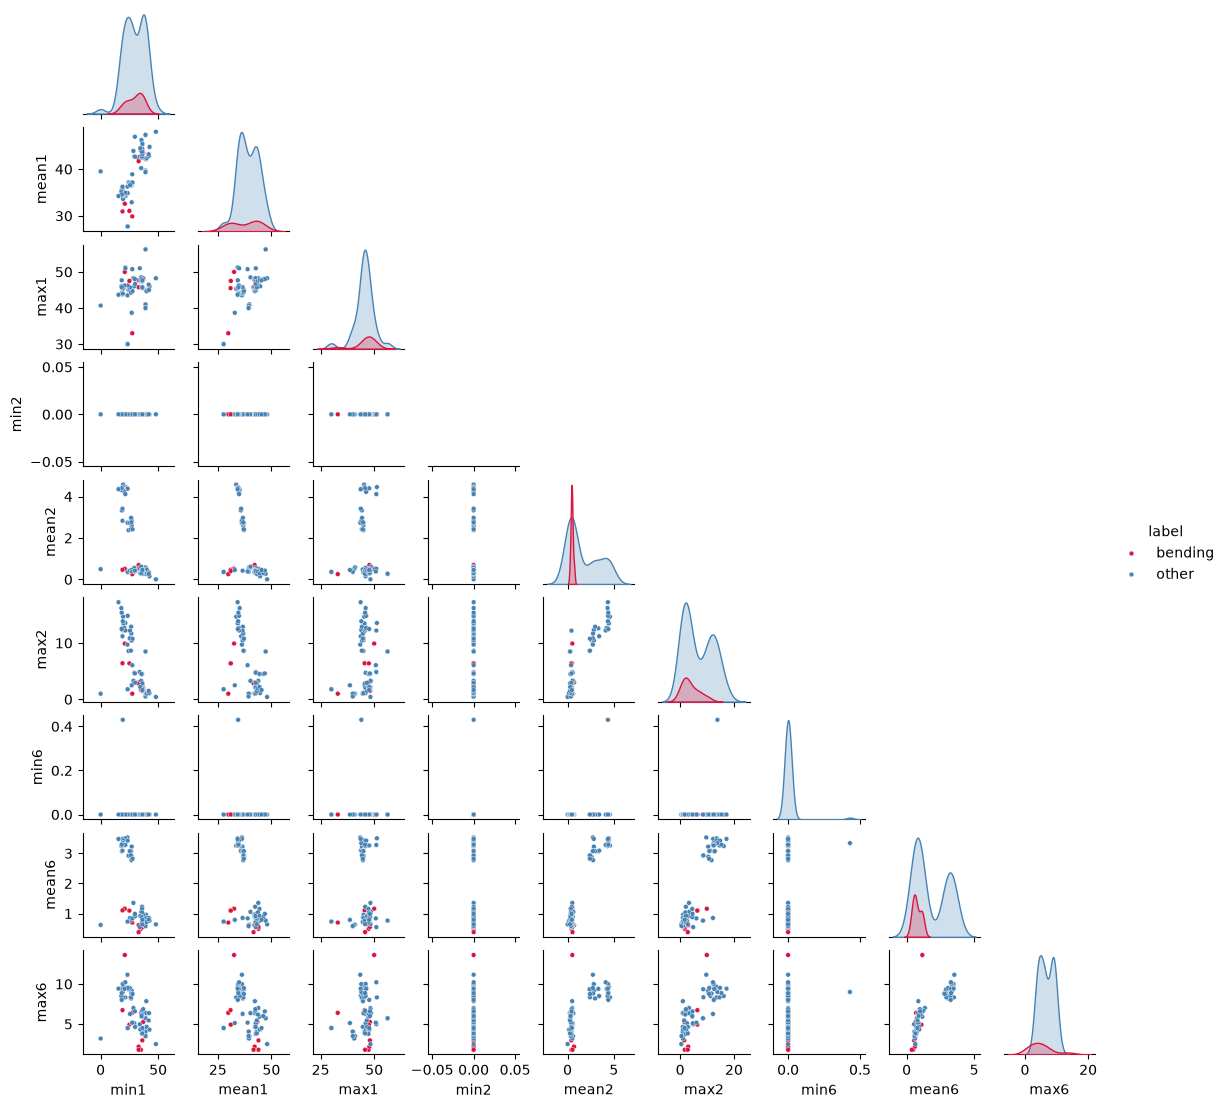

In [8]:
def pair_plot(l):
    X, y = get_xy(l, 'train')
    cols = [c for c in X.columns if c.split('_p')[0][-1] in '126']
    df = X[cols].assign(label=np.where(y == 1, 'bending', 'other'))
    sns.pairplot(df, hue='label', palette={'bending': 'crimson', 'other': 'steelblue'},
                 corner=True, height=1.25 if l == 1 else 0.9, plot_kws={'s': 12})
    plt.show()

pair_plot(1)

- Bending (red) sits in a compact region of most panels. Its `var_rss12` and `var_rss23` features (series 2 and 6) are small, with mean2 between 0.26 and 0.70 and mean6 below 1.2, and its min1 is never below 19.
- No single feature separates the classes perfectly, but pairs such as (mean1, mean6) or (min1, mean2) almost do. So a linear classifier on a few features should work well.
- `min2` is 0 for every instance (the variance always drops to 0 at some point), so it carries no information.

#### ii. Same plots after breaking each series into two halves

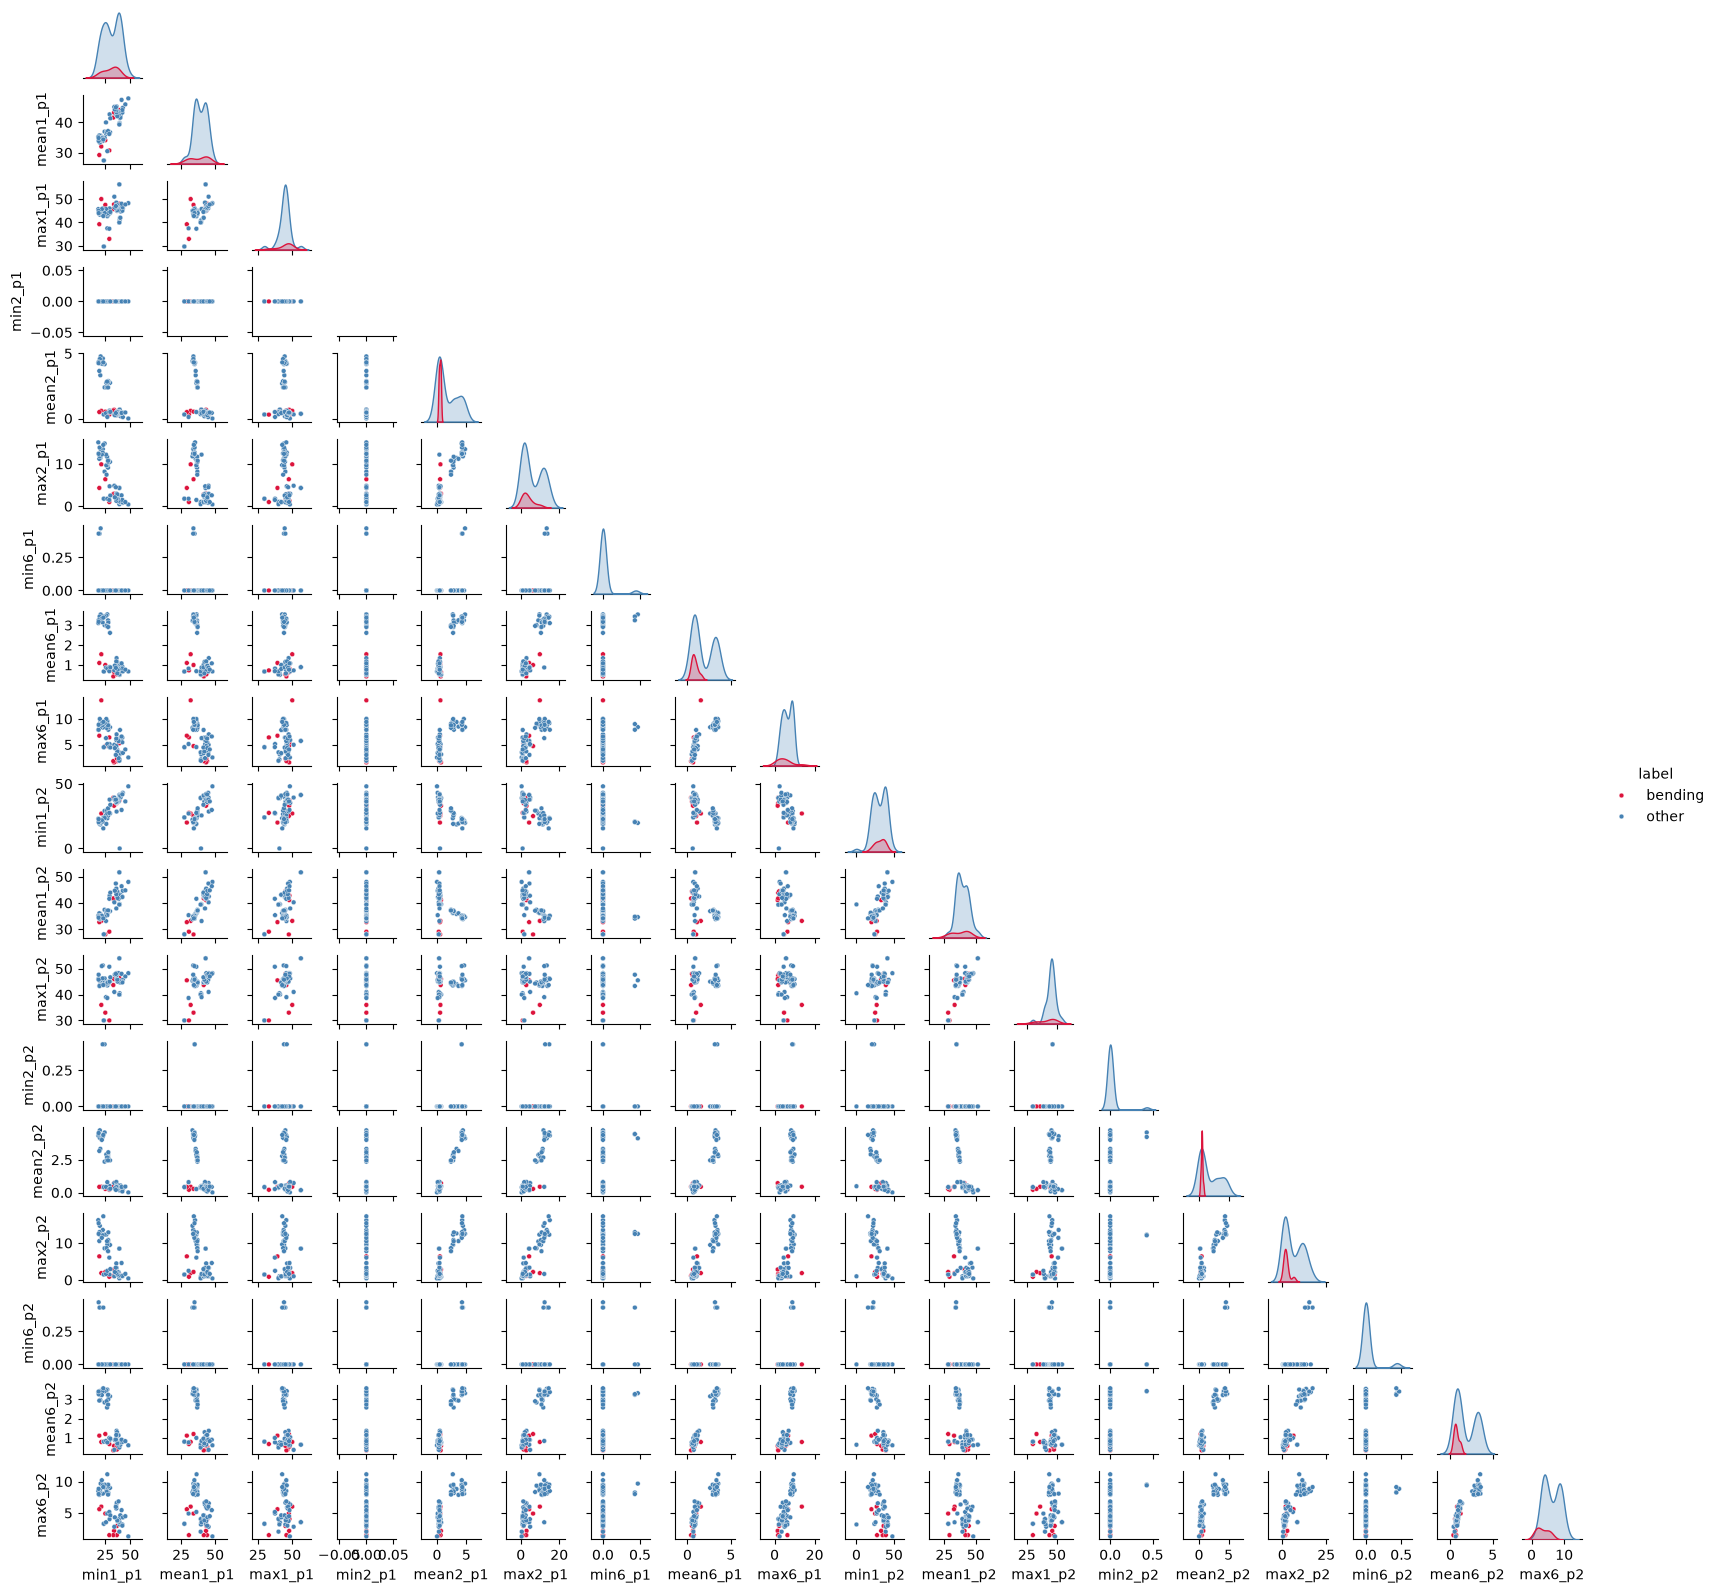

,min1,mean1,max1,min2,mean2,max2,min6,mean6,max6
"corr(half 1, half 2)",0.768,0.884,0.656,NaN,0.99,0.893,0.235,0.984,0.799


In [9]:
pair_plot(2)

X2, _ = get_xy(2, 'train')
halves = pd.Series({f'{n}{k}': X2[f'{n}{k}_p1'].corr(X2[f'{n}{k}_p2'])
                    for k in (1, 2, 6) for n in CHOSEN}, name='corr(half 1, half 2)')
display(halves.round(3).to_frame().T)

There is no considerable difference from 2(a)i. Each half shows the same separation pattern as the full series. Most features of the two halves are strongly correlated (0.66 to 0.99 in the table), because each activity is fairly stationary over the 2-minute recording. The exception is min6 (0.24), which is close to 0 in almost every half. `min2` is always 0, so its correlation is undefined (NaN). Splitting mainly duplicates information rather than adding new information.

#### iii. Choosing (l, p) with recursive feature elimination and 5-fold stratified CV

- **Wrong way:** choose the p features (by p-values or RFE) using the *whole* training set, then run cross-validation only on the final logistic regression. The held-out folds were already used to select the features, so the CV error is optimistically biased.
- **Right way:** feature selection is part of the model. Inside **each** fold, run RFE on the 4 training folds only, fit the logistic regression on the selected features, and score it on the held-out fold. Average over folds for every (l, p) pair and pick the best pair.
- **Stratified CV:** only 9 of the 69 training instances are bending, so plain K-fold could give a fold with very few or no bending cases. Stratified K-fold keeps the class proportions (about 13% bending) the same in every fold. I use it.

To keep it fast, RFE (step = 1) is run once per fold with `n_features_to_select=1`. Its `ranking_` gives the full elimination order, so the top-p ranked features are exactly the set RFE would keep for any p.

In [10]:
def cv_rfe(l):
    X, y = get_xy(l, 'train')
    X, y = X.to_numpy(), y.to_numpy()
    n = X.shape[1]
    correct = np.zeros(n)                          # correct[p-1] = correct held-out predictions with p features
    for tr, va in SKF.split(X, y):
        scaler = StandardScaler().fit(X[tr])
        Xtr, Xva = scaler.transform(X[tr]), scaler.transform(X[va])
        order = np.argsort(RFE(logreg(), n_features_to_select=1, step=1).fit(Xtr, y[tr]).ranking_, kind='stable')
        for p in range(1, n + 1):
            cols = order[:p]
            m = logreg().fit(Xtr[:, cols], y[tr])
            correct[p - 1] += (m.predict(Xva[:, cols]) == y[va]).sum()
    return correct / len(y)

rfe_rows = []
for l in LS:
    acc = cv_rfe(l)
    p = int(np.argmax(acc)) + 1                    # smallest p reaching the best accuracy
    rfe_rows.append({'l': l, 'best p': p, 'CV accuracy': acc[p - 1], 'features available': len(acc)})

rfe_table = pd.DataFrame(rfe_rows).set_index('l')
display(rfe_table.round(4).T)

best_row = rfe_table.reset_index().sort_values(['CV accuracy', 'l', 'best p'], ascending=[False, True, True]).iloc[0]
best_l, best_p, rfe_cv_acc = int(best_row['l']), int(best_row['best p']), best_row['CV accuracy']
print(f'Best pair: l = {best_l}, p = {best_p}, CV accuracy = {rfe_cv_acc:.4f}')

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best p,11.0000,5.0000,1.0000,7.000,4.000,6.0000,6.0000,1.0000,3.000,4.0000,6.000,4.000,3.000,8.000,32.000,1.0000,24.000,1.000,6.0000,5.0000
CV accuracy,0.9855,0.9565,0.9565,0.971,0.942,0.9565,0.9565,0.9275,0.971,0.9275,0.942,0.971,0.942,0.942,0.942,0.9565,0.942,0.942,0.9855,0.9855
features available,18.0000,36.0000,54.0000,72.000,90.000,108.0000,126.0000,144.0000,162.000,180.0000,198.000,216.000,234.000,252.000,270.000,288.0000,306.000,324.000,342.0000,360.0000


Best pair: l = 1, p = 11, CV accuracy = 0.9855


#### iv. Confusion matrix, ROC and AUC on the training data; coefficients and p-values

Selected features: ['min1', 'mean1', 'max2', 'min3', 'mean3', 'mean4', 'max4', 'min5', 'mean5', 'max5', 'mean6']


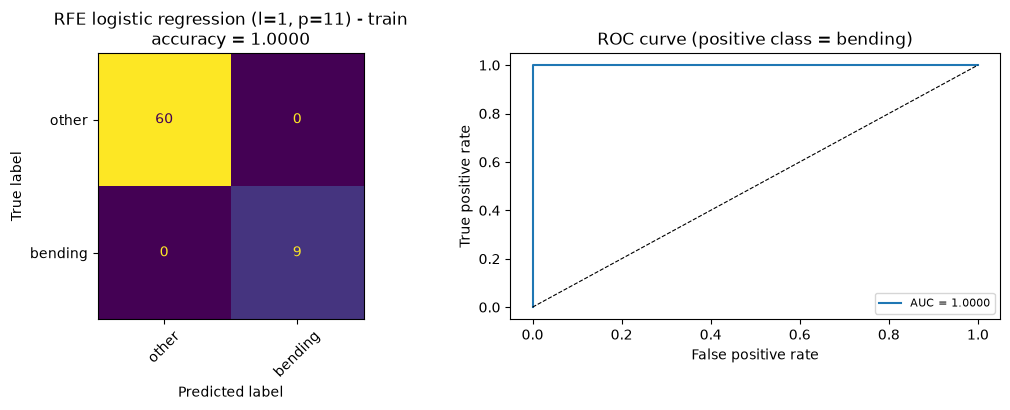

In [11]:
Xtr, ytr = get_xy(best_l, 'train')
Xte, yte = get_xy(best_l, 'test')

rfe_model = make_pipeline(StandardScaler(), RFE(logreg(), n_features_to_select=best_p))
rfe_model.fit(Xtr, ytr)
selected = list(Xtr.columns[rfe_model[-1].support_])
print('Selected features:', selected)

rfe_train = report(rfe_model, Xtr, ytr, f'RFE logistic regression (l={best_l}, p={best_p}) - train')

In [12]:
# Coefficients and p-values with statsmodels (unpenalized maximum likelihood) on the standardized selected features.
sc = StandardScaler().fit(Xtr[selected])
Z = sm.add_constant(pd.DataFrame(sc.transform(Xtr[selected]), columns=selected, index=Xtr.index))
fit = sm.Logit(ytr, Z).fit(disp=0, maxiter=200)
display(pd.DataFrame({'beta': fit.params, 'std err': fit.bse, 'z': fit.tvalues, 'p-value': fit.pvalues}).round(4))

,beta,std err,z,p-value
const,-37.6923,1.731875e+05,-0.0002,0.9998
min1,-10.8008,2.877981e+05,-0.0000,1.0000
mean1,-1.8765,5.770939e+05,-0.0000,1.0000
max2,-12.3560,2.061074e+05,-0.0001,1.0000
min3,-7.8646,9.811439e+05,-0.0000,1.0000
mean3,-7.4473,2.341065e+05,-0.0000,1.0000
mean4,-14.6145,3.258493e+06,-0.0000,1.0000
max4,8.8576,4.249001e+05,0.0000,1.0000
min5,24.4906,1.680715e+06,0.0000,1.0000
mean5,-1.1558,2.277952e+06,-0.0000,1.0000


#### v. Test set results

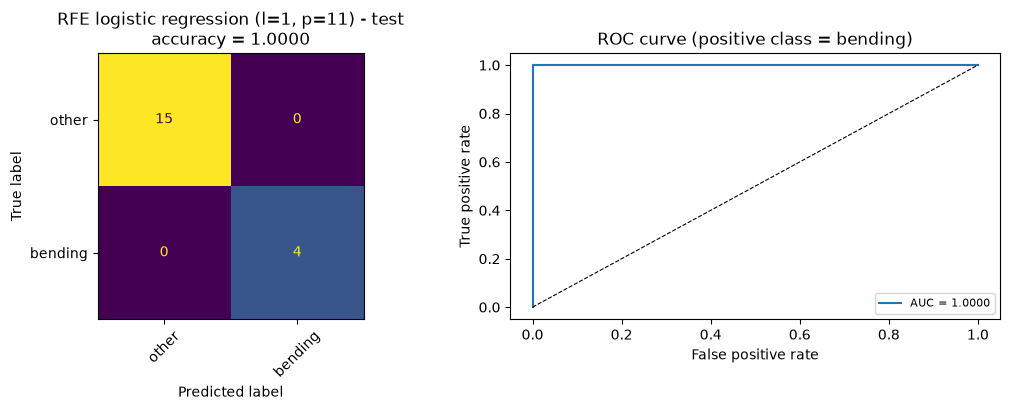

,accuracy
5-fold CV,0.9855
test set,1.0000


In [13]:
rfe_test = report(rfe_model, Xte, yte, f'RFE logistic regression (l={best_l}, p={best_p}) - test')
display(pd.DataFrame({'accuracy': [rfe_cv_acc, rfe_test[0]]}, index=['5-fold CV', 'test set']).round(4))

In [14]:
print(f'CV accuracy {rfe_cv_acc:.4f} vs. test accuracy {rfe_test[0]:.4f} '
      f'({len(yte)} test instances, so one error = {1/len(yte):.4f}).')

CV accuracy 0.9855 vs. test accuracy 1.0000 (19 test instances, so one error = 0.0526).


- The best pair is **l = 1, p = 11** (CV accuracy 98.55%, i.e. 1 of 69 held-out predictions wrong). l = 19 and l = 20 tie with it, and I keep the smallest l because it is the simplest model.
- On the test set the classifier gets all **19 of 19** instances right (100%), slightly better than its CV accuracy.
- The two numbers are consistent. With only 19 test instances, one error changes accuracy by 5.3%, and the CV estimate (the best of many (l, p) pairs) has its own variance. Both show that bending is very easy to separate from the other activities.

#### vi. Are the classes separated enough to make the estimates unstable?

In [15]:
def coef_growth(X, y):
    Xs = StandardScaler().fit_transform(X)
    out = {}
    for it in (10, 100, 1000, 10000):
        m = LogisticRegression(C=np.inf, max_iter=it, tol=1e-12).fit(Xs, y)
        out[f'max|beta|, {it} iter'] = np.abs(m.coef_).max()
    out['train accuracy'] = m.score(Xs, y)
    return out

Xall1, yall1 = get_xy(1, 'train')
display(pd.DataFrame({f'selected model (l={best_l}, p={best_p})': coef_growth(Xtr[selected], ytr),
                      f'all {Xall1.shape[1]} features, l=1': coef_growth(Xall1, yall1)}).T.round(3))

,"max|beta|, 10 iter","max|beta|, 100 iter","max|beta|, 1000 iter","max|beta|, 10000 iter",train accuracy
"selected model (l=1, p=11)",4.465,23.392,23.392,23.392,1.0
"all 18 features, l=1",4.087,19.703,19.703,19.703,1.0


**Yes.** Both the selected 11-feature model and the full 18-feature model reach **100% training accuracy**, so the training classes are perfectly linearly separable. Under perfect separation the likelihood keeps increasing as the coefficients grow, so the MLE is not finite (it lies at infinity):
- The coefficients depend on when the optimizer stops. max|β| jumps from about 4 after 10 iterations to about 20 after 100, and only stops there because the gradient becomes numerically zero, not because a true maximum was reached.
- In 2(a)iv, statsmodels reports standard errors of order 10⁵-10⁶ and p-values ≈ 1 for every coefficient. Those p-values are meaningless, which is a symptom of the instability, not evidence that the features are useless.

This is why `max_iter` is kept small (as the assignment suggests), and why the L1-penalized model in 2(b) is more reliable here.

#### vii. Class imbalance and case-control sampling

In [16]:
display(pd.DataFrame({'train': ytr.value_counts(), 'test': yte.value_counts()}).rename(index={0: 'other', 1: 'bending'}))

,train,test
bending,,
other,60,15
bending,9,4


The classes are imbalanced: about 13% of the training instances are bending. In case-control sampling I keep all bending (case) instances, randomly draw the same number of "other" (control) instances, fit the logistic regression on this balanced sample, and then correct the intercept for the true prevalence π:

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi}$$

where $\tilde\pi = 0.5$ is the case fraction in the sample. The slope coefficients do not need adjusting.

pi = 0.1304, sample pi = 0.50; intercept 1.7150 -> -0.1821


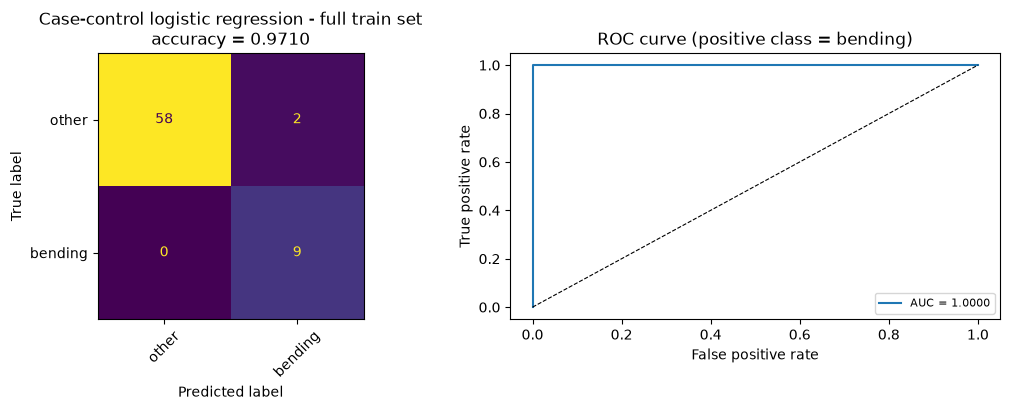

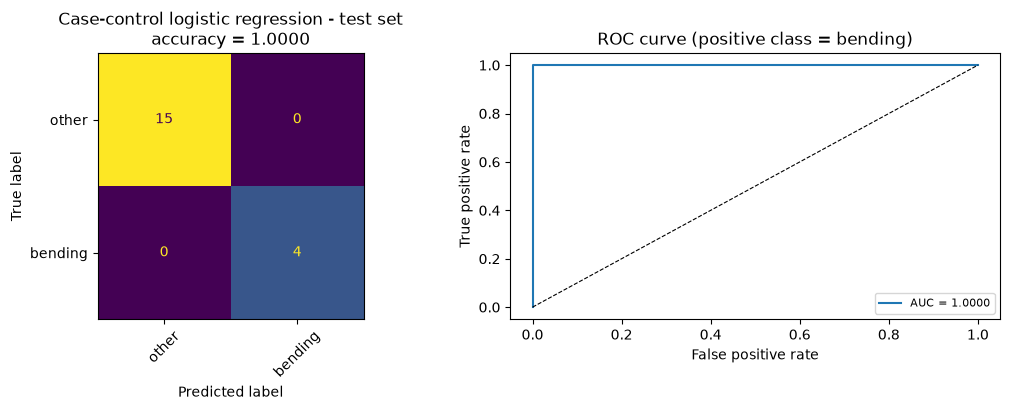

Case-control model: train accuracy 0.9710, AUC 1.0000; test accuracy 1.0000, AUC 1.0000


In [17]:
rng = np.random.RandomState(552)
cases = ytr.index[ytr == 1]
controls = rng.choice(ytr.index[ytr == 0], size=len(cases), replace=False)
cc_idx = np.concatenate([cases, controls])

cc_model = make_pipeline(StandardScaler(), logreg()).fit(Xtr.loc[cc_idx, selected], ytr.loc[cc_idx])
pi, pi_s = ytr.mean(), ytr.loc[cc_idx].mean()
b0 = cc_model[-1].intercept_[0]
logit = lambda q: np.log(q) - np.log1p(-q)
cc_model[-1].intercept_ += logit(pi) - logit(pi_s)
print(f'pi = {pi:.4f}, sample pi = {pi_s:.2f}; intercept {b0:.4f} -> {cc_model[-1].intercept_[0]:.4f}')

cc_train = report(cc_model, Xtr[selected], ytr, 'Case-control logistic regression - full train set')
cc_test = report(cc_model, Xte[selected], yte, 'Case-control logistic regression - test set')
print(f'Case-control model: train accuracy {cc_train[0]:.4f}, AUC {cc_train[1]:.4f}; '
      f'test accuracy {cc_test[0]:.4f}, AUC {cc_test[1]:.4f}')

The case-control model is trained on only 18 instances (9 bending, 9 other). It still ranks every training and test instance correctly (AUC = 1.0) and classifies the whole test set correctly. Its training accuracy (97.1%) is a little lower than the full model's, because it saw fewer "other" examples. The intercept correction moves its predicted probabilities back to the true 13% bending rate.

### 2(b) Binary classification using L1-penalized logistic regression

#### i. Choosing (l, C) with 5-fold stratified CV

In [18]:
C_GRID = np.logspace(-2, 3, 11)

def l1_model(C=1.0, solver='liblinear'):
    # l1_ratio=1 makes the penalty pure L1 (lasso); features are standardized first.
    lasso = LogisticRegression(C=C, l1_ratio=1, solver=solver, max_iter=5000, random_state=552)
    return make_pipeline(StandardScaler(), lasso)

def tune_C(target, solver):
    # For every l, grid-search C with stratified 5-fold CV. Returns one row per l.
    table = {}
    for l in LS:
        X, y = get_xy(l, 'train', target)
        search = GridSearchCV(l1_model(solver=solver), {'logisticregression__C': C_GRID},
                              cv=SKF, scoring='accuracy', n_jobs=-1).fit(X, y)
        nonzero = (search.best_estimator_[-1].coef_ != 0).any(axis=0).sum()
        table[l] = pd.Series({'C': search.best_params_['logisticregression__C'],
                              'mean CV acc': search.best_score_, 'features kept': nonzero})
    table = pd.DataFrame(table).T.rename_axis('l')
    l_star = int(table['mean CV acc'].round(8).idxmax())   # ties go to the smallest l
    return table, l_star, table.loc[l_star, 'C'], table.loc[l_star, 'mean CV acc']

l1_table, l1_l, l1_C, l1_cv_acc = tune_C('bending', 'liblinear')
display(l1_table.round(4).T)
print(f'Chosen: l = {l1_l}, C = {l1_C:.4g}, mean CV accuracy = {l1_cv_acc:.4f}')

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
C,1.0000,10.0000,0.3162,1.0000,10.0000,10.0000,1.0000,3.1623,0.3162,1000.0000,3.1623,1.0000,1.0000,0.3162,0.3162,0.3162,31.6228,31.6228,3.1623,1.0000
mean CV acc,0.9857,0.9571,0.9714,0.9714,0.9429,0.9571,0.9714,0.9275,0.9286,0.9143,0.9714,0.9714,0.9714,0.9429,0.9286,0.9286,0.9571,0.9571,0.9571,0.9714
features kept,6.0000,10.0000,5.0000,9.0000,13.0000,13.0000,9.0000,13.0000,8.0000,51.0000,7.0000,5.0000,8.0000,7.0000,9.0000,9.0000,20.0000,17.0000,11.0000,9.0000


Chosen: l = 1, C = 1, mean CV accuracy = 0.9857


,beta (standardized)
mean1,-0.4020
max2,-0.0266
mean3,-0.1471
min5,1.1571
max5,1.8007
mean6,-0.8337


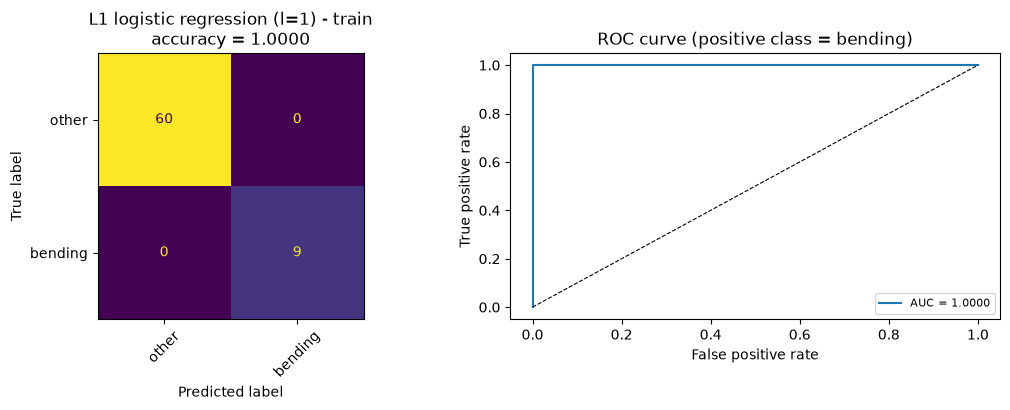

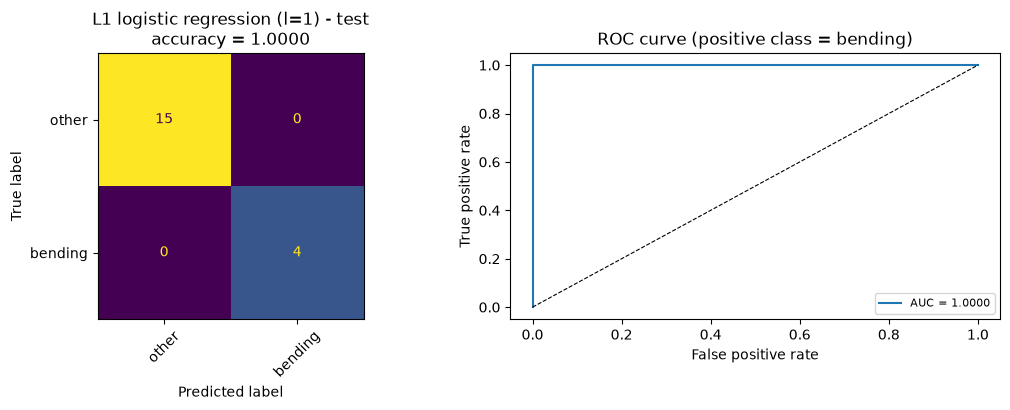

In [19]:
Xtr1, ytr1 = get_xy(l1_l, 'train')
Xte1, yte1 = get_xy(l1_l, 'test')
l1_fit = l1_model(C=l1_C).fit(Xtr1, ytr1)
coefs = pd.Series(l1_fit[-1].coef_.ravel(), index=Xtr1.columns)
display(coefs[coefs != 0].to_frame('beta (standardized)').round(4))

l1_train = report(l1_fit, Xtr1, ytr1, f'L1 logistic regression (l={l1_l}) - train')
l1_test = report(l1_fit, Xte1, yte1, f'L1 logistic regression (l={l1_l}) - test')

#### ii. L1 penalty vs. variable selection with p-values / RFE

In [20]:
comparison = pd.DataFrame.from_records([
    ('RFE (backward elimination)', best_l, best_p, rfe_cv_acc, *rfe_test),
    ('Lasso (L1) logistic', l1_l, (coefs != 0).sum(), l1_cv_acc, *l1_test),
], columns=['method', 'l', '# predictors', 'mean CV acc', 'test acc', 'test AUC']).set_index('method')
display(comparison.round(4))

,l,# predictors,mean CV acc,test acc,test AUC
method,,,,,
RFE (backward elimination),1,11,0.9855,1.0,1.0
Lasso (L1) logistic,1,6,0.9857,1.0,1.0


- **Performance:** they perform the same. Both pick l = 1, both have about 98.6% CV accuracy, and both classify the test set perfectly (accuracy 1.0, AUC 1.0). The L1 model reaches this with **6 features instead of 11**, and its coefficients are finite and stable (the penalty prevents them from blowing up under separation), so it is the better model.
- **Ease of implementation:** L1 is easier. Selection happens inside a single convex fit, the CV is a standard grid search over (l, C), and no p-values (which are unreliable under separation) or nested RFE loops are needed.

### 2(c) Multi-class classification (the realistic case)

#### i. L1-penalized multinomial logistic regression

- **Multiclass confusion matrix:** with K = 7 activities it is a 7×7 table. Rows are the actual activity, columns are the predicted activity, and each cell counts how often that (actual, predicted) combination happened. Correct predictions lie on the diagonal; everything off the diagonal shows which activities get confused with which.
- **Multiclass ROC:** use one-vs-rest. For each class k, treat k as positive and all other classes as negative, then draw the ROC curve from the predicted probability of k. Summarize with the per-class AUCs and their average (macro AUC).

In [21]:
# saga supports the L1 penalty with a true multinomial (softmax) loss.
mn_table, mn_l, mn_C, mn_cv_acc = tune_C('activity', 'saga')
display(mn_table.round(4).T)
print(f'Chosen: l = {mn_l}, C = {mn_C:.4g}, mean CV accuracy = {mn_cv_acc:.4f}')

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
C,3.1623,316.2278,316.2278,316.2278,100.0000,100.0000,1000.0000,316.2278,100.0000,1000.0000,316.2278,1000.0000,1000.0000,100.0000,316.2278,316.2278,316.2278,316.2278,316.2278,316.2278
mean CV acc,0.9000,0.7692,0.8143,0.7571,0.7681,0.7571,0.7692,0.7396,0.7857,0.7681,0.7396,0.7692,0.8275,0.7846,0.7846,0.7835,0.7560,0.7692,0.7978,0.8132
features kept,14.0000,35.0000,54.0000,72.0000,90.0000,108.0000,126.0000,144.0000,162.0000,180.0000,198.0000,216.0000,234.0000,252.0000,270.0000,288.0000,306.0000,324.0000,342.0000,360.0000


Chosen: l = 1, C = 3.162, mean CV accuracy = 0.9000


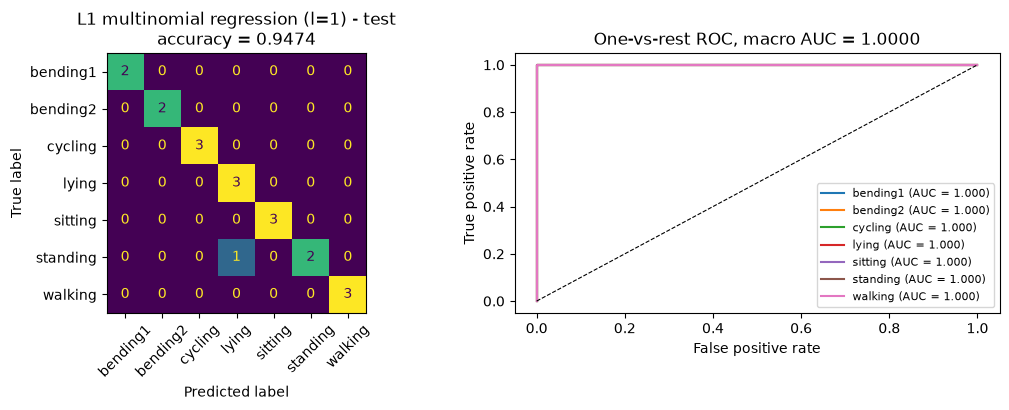

Test error = 0.0526


In [22]:
Xtrm, ytrm = get_xy(mn_l, 'train', 'activity')
Xtem, ytem = get_xy(mn_l, 'test', 'activity')
mn_fit = l1_model(C=mn_C, solver='saga').fit(Xtrm, ytrm)
mn_test = report(mn_fit, Xtem, ytem, f'L1 multinomial regression (l={mn_l}) - test')
print(f'Test error = {1 - mn_test[0]:.4f}')

#### ii. Naive Bayes (Gaussian and Multinomial)

All features (min, mean, max of RSS readings) are non-negative, so Multinomial NB can use them directly. For each model, l is chosen by the same 5-fold stratified CV.

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Gaussian NB,0.8846,0.8253,0.7110,0.7396,0.6956,0.6549,0.6945,0.7099,0.6516,0.6813,0.6802,0.6077,0.6231,0.5659,0.5505,0.4945,0.5220,0.4780,0.4912,0.5231
Multinomial NB,0.7846,0.7396,0.7396,0.7538,0.7538,0.7242,0.7681,0.7396,0.7407,0.7253,0.7242,0.7264,0.7846,0.7242,0.6967,0.7099,0.7253,0.7396,0.7407,0.7418


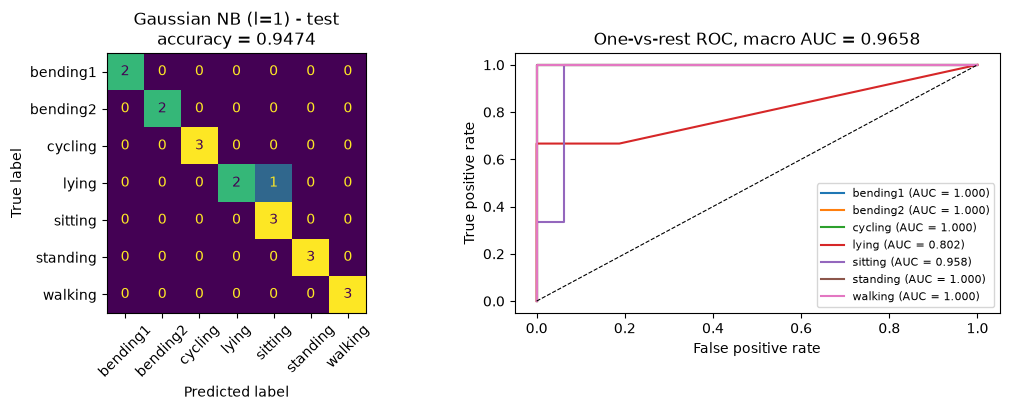

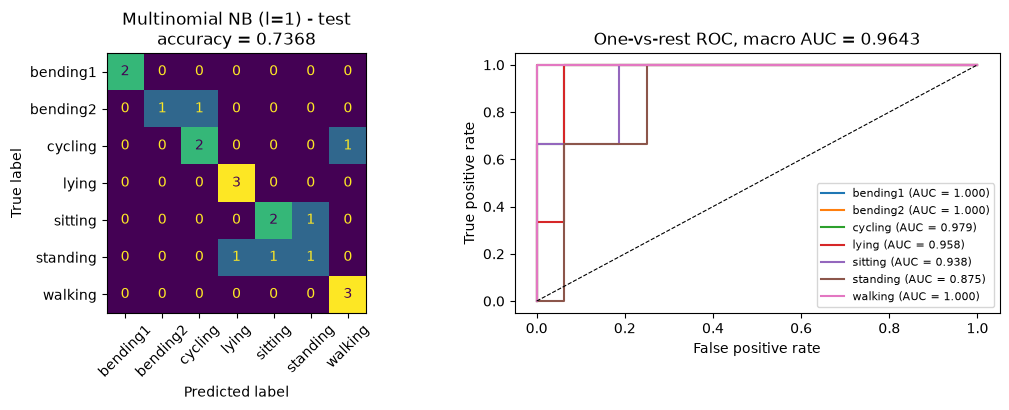

In [23]:
NB_MODELS = {'Gaussian NB': GaussianNB, 'Multinomial NB': MultinomialNB}

nb_cv = pd.DataFrame(index=pd.Index(LS, name='l'), columns=list(NB_MODELS), dtype=float)
for l in LS:
    X, y = get_xy(l, 'train', 'activity')
    for label, Model in NB_MODELS.items():
        nb_cv.loc[l, label] = cross_val_score(Model(), X, y, cv=SKF).mean()
display(nb_cv.round(4).T)

nb_res = {}
for label, Model in NB_MODELS.items():
    l_nb = int(nb_cv[label].round(8).idxmax())
    clf = Model().fit(*get_xy(l_nb, 'train', 'activity'))
    acc, a = report(clf, *get_xy(l_nb, 'test', 'activity'), f'{label} (l={l_nb}) - test')
    nb_res[label] = {'l': l_nb, 'CV accuracy': nb_cv.loc[l_nb, label], 'test accuracy': acc, 'test macro AUC': a}

#### iii. Which method is better?

In [24]:
summary = pd.DataFrame({'L1 multinomial regression': {'l': mn_l, 'CV accuracy': mn_cv_acc,
                                                       'test accuracy': mn_test[0], 'test macro AUC': mn_test[1]},
                        **nb_res}).T
summary['test error'] = 1 - summary['test accuracy']
display(summary.round(4))

,l,CV accuracy,test accuracy,test macro AUC,test error
L1 multinomial regression,1.0,0.9000,0.9474,1.0000,0.0526
Gaussian NB,1.0,0.8846,0.9474,0.9658,0.0526
Multinomial NB,1.0,0.7846,0.7368,0.9643,0.2632


- All three models do best at **l = 1**. Splitting the series only adds correlated features.
- **Gaussian vs. Multinomial NB:** Gaussian NB is much better (test accuracy 94.7% vs. 73.7%, CV 88.5% vs. 78.5%). The features are continuous RSS statistics, which suit a per-class normal model. Multinomial NB treats them as word-count-like frequencies, which does not match the data.
- **Best method: L1-penalized multinomial logistic regression.** It ties with Gaussian NB on the test set (18 of 19 correct, test error 5.3%), but has the highest CV accuracy (90.0%) and a perfect test macro AUC (1.0 vs. 0.966). Naive Bayes assumes the features are independent within each class, which is clearly false here (min, mean and max of the same series are strongly correlated). The discriminative L1 model does not need that assumption and also drops redundant features.

## 3. ISLR 4.8.3: QDA with one predictor gives a quadratic Bayes classifier

Suppose there is one predictor and, in class $k$, $X \sim N(\mu_k, \sigma_k^2)$ with a class-specific variance. With prior $\pi_k$, Bayes' theorem gives

$$p_k(x) = \Pr(Y=k \mid X=x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The Bayes classifier assigns $x$ to the class with the largest $p_k(x)$. The denominator does not depend on $k$, and $\log$ is increasing, so this is the same as maximizing $\log(\pi_k f_k(x))$:

$$\log(\pi_k f_k(x)) = \log\pi_k - \log\sqrt{2\pi} - \log\sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Dropping the constant $\log\sqrt{2\pi}$ (it is the same for every class) and expanding the square gives the discriminant

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k.$$

In LDA, all $\sigma_k$ are equal, so the $-x^2/(2\sigma^2)$ term is the same for every class and cancels when classes are compared, leaving a linear function of $x$. Here $\sigma_k$ differs between classes, so the coefficient $-1/(2\sigma_k^2)$ of $x^2$ differs, and the boundary $\delta_k(x) = \delta_l(x)$ between two classes is

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + c_{kl} = 0,$$

where $c_{kl}$ collects the terms without $x$, and the $x^2$ coefficient is non-zero whenever $\sigma_k \ne \sigma_l$. **The Bayes classifier is therefore quadratic in $x$, not linear.** $\blacksquare$

## 4. ISLR 4.8.7: Probability that a company issues a dividend

Given: $\mu_{\text{Yes}} = 10$, $\mu_{\text{No}} = 0$, common variance $\sigma^2 = 36$, $\pi_{\text{Yes}} = 0.8$, $\pi_{\text{No}} = 0.2$, and $x = 4$.

By Bayes' theorem with normal densities, the factor $\frac{1}{\sqrt{2\pi\sigma^2}}$ is the same for both classes and cancels:

$$\Pr(\text{Yes} \mid X=4) = \frac{\pi_{\text{Yes}}\, e^{-(4-10)^2/(2\cdot36)}}{\pi_{\text{Yes}}\, e^{-(4-10)^2/72} + \pi_{\text{No}}\, e^{-(4-0)^2/72}} = \frac{0.8\,e^{-0.5}}{0.8\,e^{-0.5} + 0.2\,e^{-0.2222}}$$

In [25]:
num = 0.8 * np.exp(-(4 - 10) ** 2 / 72)
den = num + 0.2 * np.exp(-(4 - 0) ** 2 / 72)
print(f'numerator = {num:.4f}, denominator = {den:.4f}, P(Yes | X = 4) = {num / den:.4f}')

numerator = 0.4852, denominator = 0.6454, P(Yes | X = 4) = 0.7519


**The probability that a company with last year's percent profit X = 4 issues a dividend is about 0.752 (75.2%).**

## References
- UCI Machine Learning Repository, *Activity Recognition system based on Multisensor data fusion (AReM)*: https://archive.ics.uci.edu/dataset/366
- G. James, D. Witten, T. Hastie, R. Tibshirani, J. Taylor, *An Introduction to Statistical Learning*, 2nd ed., Ch. 4 (logistic regression, case-control sampling, LDA/QDA, Naive Bayes) and Ch. 5-6 (cross-validation, the right and wrong way to do it, lasso).
- scikit-learn user guide: logistic regression (https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression), RFE (https://scikit-learn.org/stable/modules/feature_selection.html#rfe), stratified K-fold (https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold), Naive Bayes (https://scikit-learn.org/stable/modules/naive_bayes.html), ROC for multiclass (https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html).
- statsmodels `Logit` (coefficients, standard errors and p-values): https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.html
- SciPy `bootstrap` (bootstrap confidence intervals): https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html
- T. Fawcett, "An introduction to ROC analysis," *Pattern Recognition Letters*, 27(8), 2006 (ROC/AUC, one-vs-rest for multiclass).